# ReviewLens GPT — 02 · Training (F4) & Evaluasi (F5)

## Tujuan

Notebook ini melatih **Mini-GPT decoder-only dari nol** (tanpa pretrained model, tanpa API LLM)
lalu mengevaluasinya, memakai source code di branch `main`:

| Langkah | Sumber |
|---|---|
| Preprocessing + grouped split + silver label | `scripts/prepare_data.py` |
| Vocabulary (hanya dari `train.jsonl`) | `python -m reviewlens.tokenizer` |
| Format sekuens, truncation, batching | `reviewlens.dataset` |
| Model (attention manual + causal mask) | `reviewlens.model.MiniGPT` |
| Training loop, checkpoint, evaluasi, demo | **ditulis eksplisit di notebook ini** |

Tiga eksperimen dijalankan berurutan (E1 baseline, E2 learning rate tinggi, E3 model kecil),
model terbaik dipilih berdasarkan **best validation loss**, lalu dievaluasi pada test set.

## Cara menjalankan di Kaggle

1. *Settings* → **Accelerator: GPU T4** (cukup satu GPU; proyek ini tidak memakai multi-GPU) dan **Internet: ON**.
2. *Add Input* → dataset yang berisi `Processed Dataset.csv`.
3. *Run All*. Setelah selesai, **Save Version** agar isi `/kaggle/working/runs/` tersimpan sebagai output notebook.

## Penting

- Pembanding evaluasi adalah **silver label** (hasil `labeling.label_review` berbasis aturan),
  **bukan anotasi manusia**.
- Mode uji cepat (`RL_QUICK=1`) hanya untuk memastikan notebook berjalan. Angka dari mode itu
  atau dari data sintetis **bukan hasil eksperimen**.

## Bagian 0 — Konfigurasi

- Di Kaggle (`/kaggle/working` ada): `WORK_DIR=/kaggle/working`, `INPUT_DIR=/kaggle/input`.
- Di luar Kaggle (uji lokal): `WORK_DIR` dan `INPUT_DIR` **wajib** diisi lewat environment variable
  `RL_WORK_DIR` dan `RL_INPUT_DIR`. Folder kerja harus berada di luar repository.
- `RL_QUICK=1` → mode uji cepat: 2 epoch, train di-subset 1.500 contoh, `N_EVAL=60`, warmup 20 step
  (agar jadwal warmup + cosine tetap teruji dalam beberapa puluh step).
- Mode penuh: 6 epoch, batch 64, seed 42, `N_EVAL=500`, warmup 200 step.
- Hyperparameter arsitektur tidak diubah di `config.py`; eksperimen hanya menimpa nilai lewat argumen.

In [4]:
import json
import math
import os
import platform
import random
import shutil
import subprocess
import sys
import time
from dataclasses import asdict
from pathlib import Path

ON_KAGGLE = Path("/kaggle/working").is_dir()
if ON_KAGGLE:
    WORK_DIR = Path("/kaggle/working")
    INPUT_DIR = Path("/kaggle/input")
else:
    missing_env = [k for k in ("RL_WORK_DIR", "RL_INPUT_DIR") if not os.environ.get(k)]
    if missing_env:
        raise RuntimeError(
            f"Bukan di Kaggle dan environment variable {missing_env} belum diisi. "
            "Contoh: RL_WORK_DIR=/tmp/rl_work RL_INPUT_DIR=/tmp/rl_input"
        )
    WORK_DIR = Path(os.environ["RL_WORK_DIR"])
    INPUT_DIR = Path(os.environ["RL_INPUT_DIR"])
WORK_DIR = WORK_DIR.resolve()
INPUT_DIR = INPUT_DIR.resolve()
WORK_DIR.mkdir(parents=True, exist_ok=True)

QUICK_TEST = os.environ.get("RL_QUICK", "0") == "1"

SEED = 42
BATCH_SIZE = 64
EPOCHS = 2 if QUICK_TEST else 6
TRAIN_SUBSET = 1500 if QUICK_TEST else None    # None = seluruh train
N_EVAL = 60 if QUICK_TEST else 500             # contoh test untuk metrik berbasis generate
WARMUP_STEPS = 20 if QUICK_TEST else 200
MIN_LR_RATIO = 0.1                             # cosine decay sampai 10% LR awal
RESUME = True                                  # lanjutkan dari last.pt jika ada (lihat Bagian 6)

EXPERIMENTS = [
    {"name": "E1_baseline",    "model": {},                                          "lr": 3e-4},
    {"name": "E2_lr_tinggi",   "model": {},                                          "lr": 1e-3},
    {"name": "E3_model_kecil", "model": {"n_layer": 2, "d_model": 128, "d_ff": 512}, "lr": 3e-4},
]

# RL_REPO_URL hanya untuk uji lokal/offline (mis. path repo lokal); di Kaggle pakai default GitHub.
REPO_URL = os.environ.get("RL_REPO_URL", "https://github.com/nidahijriaa/reviewlens-mini-gpt.git")
BRANCH = "main"
REPO_DIR = WORK_DIR / "reviewlens-mini-gpt"
DATA_DIR = WORK_DIR / "data" / "processed"
RUNS_DIR = WORK_DIR / "runs"
CHILD_ENV = {**os.environ, "PYTHONIOENCODING": "utf-8"}   # ulasan bisa berisi emoji
os.environ["PYTHONIOENCODING"] = "utf-8"

print(f"Lingkungan  : {'Kaggle' if ON_KAGGLE else 'lokal'}")
print(f"Mode        : {'QUICK_TEST (bukan hasil eksperimen)' if QUICK_TEST else 'penuh'}")
print(f"WORK_DIR    : {WORK_DIR}")
print(f"INPUT_DIR   : {INPUT_DIR}")
print(f"EPOCHS={EPOCHS}  BATCH_SIZE={BATCH_SIZE}  SEED={SEED}  N_EVAL={N_EVAL}  "
      f"TRAIN_SUBSET={TRAIN_SUBSET}  WARMUP_STEPS={WARMUP_STEPS}")
for exp in EXPERIMENTS:
    print(f"  {exp['name']:15s} lr={exp['lr']:.0e}  override model={exp['model'] or 'default config.py'}")

CHECKS = {}


def check(name, ok, detail=""):
    """Pemeriksaan keras: dicatat ke CHECKS dan dirangkum di Bagian 12."""
    CHECKS[name] = bool(ok)
    print(f"[{'PASS' if ok else 'FAIL'}] {name}" + (f" -- {detail}" if detail else ""))
    if not ok:
        raise AssertionError(f"Pemeriksaan gagal: {name} {detail}")

Lingkungan  : Kaggle
Mode        : penuh
WORK_DIR    : /kaggle/working
INPUT_DIR   : /kaggle/input
EPOCHS=6  BATCH_SIZE=64  SEED=42  N_EVAL=500  TRAIN_SUBSET=None  WARMUP_STEPS=200
  E1_baseline     lr=3e-04  override model=default config.py
  E2_lr_tinggi    lr=1e-03  override model=default config.py
  E3_model_kecil  lr=3e-04  override model={'n_layer': 2, 'd_model': 128, 'd_ff': 512}


## Bagian 1 — Source code (branch `main`)

- Belum ada → `git clone --branch main --single-branch`.
- Sudah ada → setara `git pull` yang aman: berhenti jika ada perubahan lokal, lalu
  `git fetch origin main` dan memindahkan branch lokal `main` ke `origin/main`.
  Tidak ada `add`, `commit`, `push`, atau `merge`.
- Commit hash dicatat untuk `results.json`. `src/` ditambahkan ke `sys.path`, modul `reviewlens`
  yang mungkin sudah ter-import dibuang agar kode hasil clone yang dipakai.

In [5]:
def run_git(*args, cwd=None):
    res = subprocess.run(["git", *args], cwd=cwd, capture_output=True, text=True)
    if res.returncode != 0:
        raise RuntimeError(f"`git {' '.join(args)}` gagal (exit {res.returncode}):\n{res.stderr.strip()}")
    return res.stdout.strip()


def _norm_url(url):
    url = str(url).strip().rstrip("/")
    return url[:-4] if url.endswith(".git") else url


if shutil.which("git") is None:
    raise RuntimeError("Perintah `git` tidak tersedia.")

if not REPO_DIR.exists():
    print(f"Clone {REPO_URL} (branch {BRANCH}) -> {REPO_DIR}")
    try:
        run_git("clone", "--branch", BRANCH, "--single-branch", REPO_URL, str(REPO_DIR))
    except RuntimeError as exc:
        raise RuntimeError("Clone gagal. Di Kaggle pastikan Internet ON di Settings.\n" + str(exc)) from exc
else:
    print(f"Repository sudah ada di {REPO_DIR}; memeriksa sebelum memperbarui.")
    if not (REPO_DIR / ".git").is_dir():
        raise RuntimeError(f"{REPO_DIR} ada tetapi bukan repository git. Periksa/hapus manual.")
    origin = run_git("remote", "get-url", "origin", cwd=REPO_DIR)
    if _norm_url(origin) != _norm_url(REPO_URL):
        raise RuntimeError(f"origin = {origin!r}, bukan {REPO_URL!r}. Tidak diperbarui otomatis.")
    dirty = run_git("status", "--porcelain", cwd=REPO_DIR)
    if dirty:
        raise RuntimeError("Ada perubahan lokal di repository; tidak ditimpa otomatis:\n" + dirty)
    run_git("fetch", "origin", BRANCH, cwd=REPO_DIR)
    run_git("checkout", "-B", BRANCH, f"origin/{BRANCH}", cwd=REPO_DIR)

REPO_COMMIT = run_git("rev-parse", "HEAD", cwd=REPO_DIR)
print("Commit :", run_git("log", "-1", "--format=%H%n         %s (%ci)", cwd=REPO_DIR))

for d in (DATA_DIR, RUNS_DIR):
    if REPO_DIR.resolve() in d.resolve().parents:
        raise RuntimeError(f"{d} tidak boleh berada di dalam repository.")

SRC_DIR = REPO_DIR / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
for name in [m for m in sys.modules if m == "reviewlens" or m.startswith("reviewlens.")]:
    del sys.modules[name]

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset

import reviewlens
from reviewlens.config import IGNORE_INDEX, ModelConfig, Paths, TrainConfig, get_device, set_seed
from reviewlens.dataset import (MAX_NEW_TOKENS, MAX_REVIEW_TOKENS, ReviewInsightDataset,
                                collate_fn, format_prompt, format_target)
from reviewlens.labeling import ASPECTS, InsightLabel, label_review
from reviewlens.model import MiniGPT
from reviewlens.preprocess import clean_text
from reviewlens.tokenizer import EOS, NEG, NONE, PAD, POS, SUG, UNK, SPECIAL_TOKENS, WordTokenizer

check("reviewlens di-import dari repo hasil clone",
      Path(reviewlens.__file__).resolve().parent == (SRC_DIR / "reviewlens").resolve(),
      reviewlens.__file__)

DEVICE = get_device()
print("\nPython :", platform.python_version(), "| torch", torch.__version__, "| pandas", pd.__version__)
print("Device :", DEVICE, f"({torch.cuda.get_device_name(0)})" if DEVICE.startswith("cuda") else "")
if ON_KAGGLE and not DEVICE.startswith("cuda") and not QUICK_TEST:
    print("PERINGATAN: GPU tidak aktif. Aktifkan Accelerator GPU T4 agar training tidak sangat lambat.")

Repository sudah ada di /kaggle/working/reviewlens-mini-gpt; memeriksa sebelum memperbarui.
Commit : a90ab6c0f12b1acbdfb0c96eedd0aeb089dd60f4
         Merge pull request #11 from nidahijriaa/docs/update-interfaces-grouped-split (2026-11-11 12:12:52 +0700)
[PASS] reviewlens di-import dari repo hasil clone -- /kaggle/working/reviewlens-mini-gpt/src/reviewlens/__init__.py

Python : 3.13.16 | torch 2.11.0+cu130 | pandas 2.3.3
Device : cuda (Tesla T4)


## Bagian 2 — Menemukan dataset

`Processed Dataset.csv` dicari di seluruh `INPUT_DIR` dengan `pathlib.rglob` (tanpa menebak folder):

- **0 kandidat** → error dengan petunjuk *Add Input*.
- **> 1 kandidat** → semua ditampilkan dan sel berhenti; isi `CSV_PATH_OVERRIDE` lalu jalankan ulang.

CSV hanya dibaca. Hash SHA-256 dicek lagi di Bagian 12.

In [6]:
import hashlib

CSV_NAME = "Processed Dataset.csv"
CSV_PATH_OVERRIDE = None   # isi HANYA jika ada lebih dari satu kandidat
ADD_INPUT_HELP = (f"Tambahkan dataset berisi '{CSV_NAME}' lewat panel kanan Kaggle: "
                  "Add Input -> pilih dataset -> Add, lalu jalankan ulang sel ini.")

if not INPUT_DIR.is_dir():
    raise FileNotFoundError(f"{INPUT_DIR} tidak ditemukan. {ADD_INPUT_HELP}")
candidates = sorted(p for p in INPUT_DIR.rglob(CSV_NAME) if p.is_file())
print(f"Kandidat '{CSV_NAME}' di bawah {INPUT_DIR}: {len(candidates)}")
for i, p in enumerate(candidates, 1):
    print(f"  [{i}] {p}  ({p.stat().st_size / 1e6:.2f} MB)")

if CSV_PATH_OVERRIDE is not None:
    CSV_PATH = Path(CSV_PATH_OVERRIDE)
    if CSV_PATH.resolve() not in {p.resolve() for p in candidates}:
        raise ValueError(f"CSV_PATH_OVERRIDE = {CSV_PATH} bukan salah satu kandidat di atas.")
elif not candidates:
    raise FileNotFoundError(f"File '{CSV_NAME}' tidak ditemukan di bawah {INPUT_DIR}. {ADD_INPUT_HELP}")
elif len(candidates) > 1:
    raise RuntimeError(f"Ditemukan {len(candidates)} file '{CSV_NAME}'. Isi CSV_PATH_OVERRIDE dengan "
                       "salah satu path di atas, lalu jalankan ulang sel ini.")
else:
    CSV_PATH = candidates[0]
print("Dataset:", CSV_PATH)


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


CSV_SHA256_BEFORE = sha256_file(CSV_PATH)
print("SHA-256:", CSV_SHA256_BEFORE)

Kandidat 'Processed Dataset.csv' di bawah /kaggle/input: 1
  [1] /kaggle/input/datasets/najwakhasanah/customer-review-indonesia/Processed Dataset.csv  (7.07 MB)
Dataset: /kaggle/input/datasets/najwakhasanah/customer-review-indonesia/Processed Dataset.csv
SHA-256: ba7efc3e98f0219de24ae1804f335f4d67bca0ac5fe7fd3e9ddc620bc6e84a21


## Bagian 3 — Preprocessing, grouped split, silver label

Menjalankan script proyek apa adanya (default: 80/10/10, seed 42, oversampling negatif hanya di train):

```
python scripts/prepare_data.py --csv <CSV_PATH> --out-dir WORK_DIR/data/processed
```

JSONL lama di folder output dihapus dulu agar tidak terbaca file basi. Stdout disimpan ke
`WORK_DIR/prepare_data_stdout.txt`.

In [7]:
def read_jsonl(path):
    with open(path, encoding="utf-8") as fh:
        return [json.loads(line) for line in fh if line.strip()]


PATHS = Paths(raw_csv=CSV_PATH, data_dir=DATA_DIR, checkpoint_dir=RUNS_DIR)
SPLIT_FILES = {"train": PATHS.train_jsonl, "val": PATHS.val_jsonl, "test": PATHS.test_jsonl}
DATA_DIR.mkdir(parents=True, exist_ok=True)
for p in [*SPLIT_FILES.values(), PATHS.vocab]:
    if p.exists():
        print("Hapus output lama:", p)
        p.unlink()

cmd = [sys.executable, str(REPO_DIR / "scripts" / "prepare_data.py"),
       "--csv", str(CSV_PATH), "--out-dir", str(DATA_DIR)]
t0 = time.time()
res = subprocess.run(cmd, cwd=REPO_DIR, capture_output=True, text=True, encoding="utf-8", env=CHILD_ENV)
(WORK_DIR / "prepare_data_stdout.txt").write_text(res.stdout + res.stderr, encoding="utf-8")
print(res.stdout)
if res.returncode != 0:
    raise RuntimeError(f"prepare_data.py gagal (exit {res.returncode}):\n{res.stderr}")
print(f"Selesai dalam {time.time() - t0:.1f} detik")

RECORDS = {s: read_jsonl(p) for s, p in SPLIT_FILES.items()}
SPLIT_COUNTS = {s: len(r) for s, r in RECORDS.items()}
print("\nJumlah record JSONL (train sudah di-oversample):")
split_table = pd.DataFrame({
    s: pd.Series([r["sentiment"] for r in recs]).value_counts() for s, recs in RECORDS.items()
}).fillna(0).astype(int).T
split_table["total"] = split_table.sum(axis=1)
display(split_table)
check("ketiga split tidak kosong", all(SPLIT_COUNTS.values()), str(SPLIT_COUNTS))

CSV        : /kaggle/input/datasets/najwakhasanah/customer-review-indonesia/Processed Dataset.csv
Output dir : /kaggle/working/data/processed
Loaded 41055 reviews, 0 empty after clean_text -> 41055 enter the split (before conflict removal)
Grouped split (seed=42, val=0.1, test=0.1):
  n_rows_input      : 41055
  n_groups          : 36189
  n_conflict_groups : 118
  n_rows_dropped    : 1845  (conflicting sentiment, removed)
  n_rows_kept       : 39210  (used for train/val/test)
  split_rows        : {'train': 31368, 'val': 3921, 'test': 3921}
  split_frac        : train 0.8000, val 0.1000, test 0.1000
  conflict_examples : 10 shown of 118
    - 'alhamdulillah berfungsi normal'
    - 'bagus kok'
    - 'barang cepat sampai'
    - 'barang good'
    - 'barang mendarat dengan selamat'
    - 'barang nya oke'
    - 'barang oke'
    - 'barang oke good'
    - 'barang oke mantap'
    - 'barang oke packing rapi'
Written (train oversampled x1.5 negatives): {'train': 34708, 'val': 3921, 'test': 3921

,positive,negative,neutral,total
train,21776,10019,2913,34708
val,2722,835,364,3921
test,2722,835,364,3921


[PASS] ketiga split tidak kosong -- {'train': 34708, 'val': 3921, 'test': 3921}


## Bagian 4 — Vocabulary (hanya dari train)

`python -m reviewlens.tokenizer --data-dir WORK_DIR/data/processed` membaca **hanya** `train.jsonl`
(ulasan + `format_target` silver label, setiap record unik dihitung sekali sehingga oversampling tidak
menaikkan frekuensi), `min_freq=3`, maksimal 10.000 token termasuk 10 token khusus.

Persentase `<unk>` pada ulasan **validation** menunjukkan seberapa banyak kata di luar vocabulary
yang akan ditemui model pada data yang tidak dilatih.

In [8]:
tok_env = {**CHILD_ENV, "PYTHONPATH": str(SRC_DIR) + os.pathsep + CHILD_ENV.get("PYTHONPATH", "")}
res = subprocess.run([sys.executable, "-m", "reviewlens.tokenizer", "--data-dir", str(DATA_DIR)],
                     cwd=REPO_DIR, capture_output=True, text=True, encoding="utf-8", env=tok_env)
print(res.stdout)
if res.returncode != 0:
    raise RuntimeError(f"Pembangunan vocabulary gagal (exit {res.returncode}):\n{res.stderr}")

VOCAB_PATH = PATHS.vocab
tokenizer = WordTokenizer.load(VOCAB_PATH)
VOCAB_SIZE = tokenizer.vocab_size
check("ID token khusus 0-9 sesuai kontrak",
      tokenizer.encode(" ".join(SPECIAL_TOKENS)) == list(range(10)))

val_words = val_unk = 0
for r in RECORDS["val"]:
    ids = tokenizer.encode(r["review"])
    val_words += len(ids)
    val_unk += sum(i == UNK for i in ids)
UNK_VAL_PCT = 100 * val_unk / max(val_words, 1)
print(f"vocab_size                 : {VOCAB_SIZE:,}")
print(f"<unk> pada ulasan validation: {UNK_VAL_PCT:.2f}% ({val_unk:,} dari {val_words:,} kata)")

train records: 34708 (31329 unique used for counting)
vocab_size   : 5970 (min_freq=3, max_size=10000)
<unk> rate on train reviews: 5.74%
saved        : /kaggle/working/data/processed/vocab.json

[PASS] ID token khusus 0-9 sesuai kontrak
vocab_size                 : 5,970
<unk> pada ulasan validation: 6.83% (3,593 dari 52,581 kata)


## Bagian 5 — Dataset dan DataLoader

- `ReviewInsightDataset` mengubah setiap record menjadi
  `<bos> <review> … <pos> … <neg> … <sug> … <eos>` dengan panjang `≤ block_size + 1`.
- `collate_fn` membentuk `x = ids[:-1]`, `y = ids[1:]`; `x` dipad `PAD (0)`, `y` dipad
  `IGNORE_INDEX (-100)`.
- Pemeriksaan: **`PAD (0)` tidak pernah muncul sebagai target** di seluruh batch train, val, dan test.

In [9]:
BLOCK_SIZE = ModelConfig(vocab_size=VOCAB_SIZE).block_size
train_full = ReviewInsightDataset(PATHS.train_jsonl, tokenizer, BLOCK_SIZE)
val_ds = ReviewInsightDataset(PATHS.val_jsonl, tokenizer, BLOCK_SIZE)
test_ds = ReviewInsightDataset(PATHS.test_jsonl, tokenizer, BLOCK_SIZE)
if TRAIN_SUBSET is not None and TRAIN_SUBSET < len(train_full):
    subset_idx = np.random.default_rng(SEED).permutation(len(train_full))[:TRAIN_SUBSET]
    train_ds = Subset(train_full, sorted(subset_idx.tolist()))
else:
    train_ds = train_full
print(f"block_size={BLOCK_SIZE} | train {len(train_ds):,} (dari {len(train_full):,}) | "
      f"val {len(val_ds):,} | test {len(test_ds):,}")


def make_loader(ds, shuffle, epoch=0):
    """Shuffle deterministik per epoch: generator di-seed dengan SEED + epoch."""
    gen = torch.Generator().manual_seed(SEED + epoch) if shuffle else None
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, generator=gen, collate_fn=collate_fn)


val_loader = make_loader(val_ds, shuffle=False)
test_loader = make_loader(test_ds, shuffle=False)

x, y = next(iter(make_loader(train_ds, shuffle=True, epoch=1)))
print(f"\nSatu batch: x {tuple(x.shape)} {x.dtype} | y {tuple(y.shape)} {y.dtype}")
print("x[0][:16] :", x[0][:16].tolist())
print("y[0][:16] :", y[0][:16].tolist())
print("\nDecode satu contoh sekuens:")
print(tokenizer.decode(train_ds[0]))

n_pad_target, n_ignore = 0, 0
for loader in (make_loader(train_full, shuffle=False), val_loader, test_loader):
    for xb, yb in loader:
        n_pad_target += int((yb == PAD).sum())
        n_ignore += int((yb == IGNORE_INDEX).sum())
        assert torch.all(xb[yb == IGNORE_INDEX] == PAD)
check("PAD (0) tidak pernah menjadi target (train/val/test)", n_pad_target == 0,
      f"posisi y==PAD: {n_pad_target}, posisi y==IGNORE_INDEX: {n_ignore:,}")
check("x.shape == y.shape dan T <= block_size", x.shape == y.shape and x.shape[1] <= BLOCK_SIZE)

block_size=128 | train 34,708 (dari 34,708) | val 3,921 | test 3,921

Satu batch: x (64, 60) torch.int64 | y (64, 60) torch.int64
x[0][:16] : [2, 4, 78, 26, 110, 5, 9, 6, 64, 39, 40, 19, 20, 7, 33, 11]
y[0][:16] : [4, 78, 26, 110, 5, 9, 6, 64, 39, 40, 19, 20, 7, 33, 11, 65]

Decode satu contoh sekuens:
<bos> <review> barang mendarat dengan selamat di <unk> kota layar tidak pecah remot berfungsi sambungan <unk> k hp baik overall baik semoga awet <pos> kualitas produk bagus <sep> produk berfungsi dengan baik <neg> <none> <sug> <none> <eos>
[PASS] PAD (0) tidak pernah menjadi target (train/val/test) -- posisi y==PAD: 0, posisi y==IGNORE_INDEX: 2,501,489
[PASS] x.shape == y.shape dan T <= block_size


## Bagian 6 — Fungsi training

Semua komponen ditulis eksplisit di sini (belum ada `train.py`):

| Fungsi | Isi |
|---|---|
| `lr_at(step, train_cfg, total_steps)` | warmup linear `warmup_steps`, lalu cosine decay sampai `MIN_LR_RATIO` (10%) × LR awal; fungsi murni dari `step` |
| `estimate_loss(model, loader, device)` | `cross_entropy(reduction="sum")` dibagi jumlah token valid (`y != IGNORE_INDEX`) — rata-rata **per token**, bukan rata-rata per batch |
| `configure_optimizer` | AdamW `betas=(0.9, 0.95)`; weight decay 0.1 **hanya** untuk parameter berdimensi ≥ 2 |
| `save_checkpoint` / `load_checkpoint` | 7 kunci INTERFACES §9.1, ditulis ke `.tmp` lalu `os.replace` (atomik) |
| `train_experiment` | gradient clipping 1.0, shuffle `SEED + epoch`, val loss epoch 0 vs `ln(vocab_size)`, `best.pt` / `last.pt` / `history.json` / salinan `vocab.json` di `runs/<nama>/` |

**Resume:** jika `runs/<nama>/last.pt` ada dan `model_cfg`-nya sama, training dilanjutkan dari epoch berikutnya
(berguna jika sesi Kaggle terputus). Konfigurasi berbeda → berhenti dengan error, checkpoint lama tidak ditimpa
diam-diam. `RESUME = False` di Bagian 0 untuk memulai ulang dengan sengaja.

`train_loss` per epoch = rata-rata per token dari batch training **dengan dropout aktif**, sehingga bisa sedikit
lebih tinggi daripada val loss.

In [10]:
CKPT_KEYS = ("model_state", "optimizer_state", "model_cfg", "epoch", "step", "best_val_loss", "vocab_path")


def lr_at(step, train_cfg, total_steps):
    """Warmup linear lalu cosine decay ke MIN_LR_RATIO * lr. step dimulai dari 0."""
    base = train_cfg.lr
    warmup = max(1, train_cfg.warmup_steps)
    if step < warmup:
        return base * (step + 1) / warmup
    progress = min(1.0, (step - warmup) / max(1, total_steps - warmup))
    return base * (MIN_LR_RATIO + (1 - MIN_LR_RATIO) * 0.5 * (1 + math.cos(math.pi * progress)))


@torch.no_grad()
def estimate_loss(model, loader, device, max_batches=None):
    """Rata-rata NLL per token valid (y != IGNORE_INDEX) atas seluruh loader."""
    was_training = model.training
    model.eval()
    total, count = 0.0, 0
    for i, (xb, yb) in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        xb, yb = xb.to(device), yb.to(device)
        logits, _ = model(xb)
        total += F.cross_entropy(logits.view(-1, logits.size(-1)), yb.view(-1),
                                 ignore_index=IGNORE_INDEX, reduction="sum").item()
        count += int((yb != IGNORE_INDEX).sum())
    model.train(was_training)
    if count == 0:
        raise ValueError("loader tidak berisi token target yang valid")
    return total / count


def configure_optimizer(model, train_cfg):
    params = [p for p in model.parameters() if p.requires_grad]   # parameter tied dihitung sekali
    decay = [p for p in params if p.dim() >= 2]
    no_decay = [p for p in params if p.dim() < 2]
    return torch.optim.AdamW(
        [{"params": decay, "weight_decay": train_cfg.weight_decay},
         {"params": no_decay, "weight_decay": 0.0}],
        lr=train_cfg.lr, betas=(0.9, 0.95),
    )


def _atomic_replace(tmp, path):
    os.replace(tmp, path)


def save_checkpoint(path, model, optimizer, model_cfg, epoch, step, best_val_loss, vocab_path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save({
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "model_cfg": asdict(model_cfg),
        "epoch": int(epoch),
        "step": int(step),
        "best_val_loss": float(best_val_loss),
        "vocab_path": str(vocab_path),
    }, tmp)
    _atomic_replace(tmp, path)


def load_checkpoint(path, device):
    ckpt = torch.load(path, map_location=device, weights_only=True)
    missing = [k for k in CKPT_KEYS if k not in ckpt]
    if missing:
        raise ValueError(f"Checkpoint {path} tidak valid, kunci hilang: {missing}")
    return ckpt


def write_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=2, ensure_ascii=False), encoding="utf-8")
    _atomic_replace(tmp, path)


def train_experiment(exp):
    name = exp["name"]
    run_dir = RUNS_DIR / name
    run_dir.mkdir(parents=True, exist_ok=True)
    run_vocab = run_dir / "vocab.json"
    if run_vocab.exists() and run_vocab.read_bytes() != VOCAB_PATH.read_bytes():
        raise ValueError(f"{run_vocab} berbeda dari vocabulary saat ini. Hapus {run_dir} atau set RESUME=False.")
    shutil.copy2(VOCAB_PATH, run_vocab)

    model_cfg = ModelConfig(vocab_size=VOCAB_SIZE, **exp["model"])
    train_cfg = TrainConfig(batch_size=BATCH_SIZE, lr=exp["lr"], max_epochs=EPOCHS,
                            warmup_steps=WARMUP_STEPS, seed=SEED, device=DEVICE)
    set_seed(train_cfg.seed)
    model = MiniGPT(model_cfg).to(DEVICE)
    optimizer = configure_optimizer(model, train_cfg)
    steps_per_epoch = math.ceil(len(train_ds) / train_cfg.batch_size)
    total_steps = steps_per_epoch * train_cfg.max_epochs

    last_path, best_path = run_dir / "last.pt", run_dir / "best.pt"
    hist_path, init_path = run_dir / "history.json", run_dir / "init.json"
    start_epoch, step, best_val, history = 1, 0, float("inf"), []
    if RESUME and last_path.exists():
        ckpt = load_checkpoint(last_path, DEVICE)
        if ckpt["model_cfg"] != asdict(model_cfg):
            raise ValueError(f"model_cfg di {last_path} berbeda dari eksperimen {name}. "
                             "Hapus folder run tersebut atau set RESUME=False.")
        model.load_state_dict(ckpt["model_state"])
        optimizer.load_state_dict(ckpt["optimizer_state"])
        step, best_val, start_epoch = ckpt["step"], ckpt["best_val_loss"], ckpt["epoch"] + 1
        if hist_path.exists():
            history = [h for h in json.loads(hist_path.read_text(encoding="utf-8")) if h["epoch"] <= ckpt["epoch"]]
        print(f"[{name}] resume dari epoch {ckpt['epoch']} (step {step}, best val {best_val:.4f})")
        init = json.loads(init_path.read_text(encoding="utf-8")) if init_path.exists() else {}
    else:
        val0 = estimate_loss(model, val_loader, DEVICE)
        init = {"val_loss_epoch0": val0, "ln_vocab_size": math.log(VOCAB_SIZE)}
        write_json(init_path, init)
        print(f"[{name}] {model.num_parameters():,} parameter | epoch 0 (bobot acak): val loss {val0:.4f} "
              f"vs ln(vocab_size) = {math.log(VOCAB_SIZE):.4f} (selisih {val0 - math.log(VOCAB_SIZE):+.4f})")

    if start_epoch > train_cfg.max_epochs:
        print(f"[{name}] training sudah selesai ({train_cfg.max_epochs} epoch); dilewati.")
    for epoch in range(start_epoch, train_cfg.max_epochs + 1):
        model.train()
        t0 = time.time()
        loss_sum, tok_sum = 0.0, 0
        for xb, yb in make_loader(train_ds, shuffle=True, epoch=epoch):
            lr = lr_at(step, train_cfg, total_steps)
            for group in optimizer.param_groups:
                group["lr"] = lr
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            _, loss = model(xb, yb)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"[{name}] loss tidak finite pada step {step}: {loss.item()}")
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), train_cfg.grad_clip)
            optimizer.step()
            step += 1
            n_tok = int((yb != IGNORE_INDEX).sum())
            loss_sum += loss.item() * n_tok
            tok_sum += n_tok
        train_loss = loss_sum / tok_sum
        val_loss = estimate_loss(model, val_loader, DEVICE)
        improved = val_loss < best_val
        if improved:
            best_val = val_loss
            save_checkpoint(best_path, model, optimizer, model_cfg, epoch, step, best_val, "vocab.json")
        save_checkpoint(last_path, model, optimizer, model_cfg, epoch, step, best_val, "vocab.json")
        seconds = time.time() - t0
        history.append({"epoch": epoch, "step": step, "train_loss": train_loss, "val_loss": val_loss,
                        "lr": lr, "seconds": seconds})
        write_json(hist_path, history)
        print(f"[{name}] epoch {epoch}/{train_cfg.max_epochs} | train {train_loss:.4f} | val {val_loss:.4f} "
              f"{'*best*' if improved else '      '} | lr {lr:.2e} | {seconds:.1f}s")

    result = {
        "name": name,
        "model_cfg": asdict(model_cfg),
        "lr": train_cfg.lr,
        "n_parameters": model.num_parameters(),
        "epochs": train_cfg.max_epochs,
        "steps_per_epoch": steps_per_epoch,
        "train_examples": len(train_ds),
        "val_loss_epoch0": init.get("val_loss_epoch0"),
        "ln_vocab_size": math.log(VOCAB_SIZE),
        "history": history,
        "final_train_loss": history[-1]["train_loss"],
        "best_val_loss": best_val,
        "best_epoch": min(history, key=lambda h: h["val_loss"])["epoch"],
        "val_perplexity": math.exp(best_val),
        "duration_seconds": sum(h["seconds"] for h in history),
        "run_dir": str(run_dir),
    }
    del model, optimizer
    if DEVICE.startswith("cuda"):
        torch.cuda.empty_cache()
    return result


# --- Uji cepat komponen sebelum training sungguhan ------------------------------
_cfg = TrainConfig(lr=1e-3, warmup_steps=10)
_lrs = [lr_at(s, _cfg, 100) for s in range(100)]
check("lr_at: warmup linear lalu cosine ke 10%",
      abs(_lrs[0] - 1e-4) < 1e-12 and abs(_lrs[9] - 1e-3) < 1e-12 and abs(lr_at(100, _cfg, 100) - 1e-4) < 1e-12
      and all(a >= b for a, b in zip(_lrs[9:], _lrs[10:])),
      f"lr[0]={_lrs[0]:.1e}, lr[9]={_lrs[9]:.1e}, lr[end]={lr_at(100, _cfg, 100):.1e}")

set_seed(SEED)
_m = MiniGPT(ModelConfig(vocab_size=VOCAB_SIZE, n_layer=1, d_model=32, n_head=2, d_ff=64)).to(DEVICE).eval()
_xb, _yb = next(iter(val_loader))
with torch.no_grad():
    _, _mean = _m(_xb.to(DEVICE), _yb.to(DEVICE))
check("estimate_loss = rata-rata per token (sama dengan mean CE pada 1 batch)",
      abs(estimate_loss(_m, val_loader, DEVICE, max_batches=1) - _mean.item()) < 1e-4)
_opt = configure_optimizer(_m, TrainConfig())
check("weight decay hanya untuk parameter dim >= 2",
      all(p.dim() >= 2 for p in _opt.param_groups[0]["params"])
      and all(p.dim() < 2 for p in _opt.param_groups[1]["params"])
      and _opt.param_groups[1]["weight_decay"] == 0.0 and _opt.defaults["betas"] == (0.9, 0.95))
del _m, _opt

[PASS] lr_at: warmup linear lalu cosine ke 10% -- lr[0]=1.0e-04, lr[9]=1.0e-03, lr[end]=1.0e-04
[PASS] estimate_loss = rata-rata per token (sama dengan mean CE pada 1 batch)
[PASS] weight decay hanya untuk parameter dim >= 2


## Bagian 7 — Menjalankan ketiga eksperimen

Eksperimen dijalankan berurutan dengan seed yang sama (inisialisasi bobot dan urutan shuffle identik antar-eksperimen
untuk konfigurasi model yang sama). Setiap epoch mencetak train loss, val loss, tanda `*best*`, LR terakhir, dan waktu.

Jika satu eksperimen divergen (loss NaN/inf, mis. pada LR tinggi), eksperimen itu dicatat sebagai gagal di
`results.json` dan eksperimen berikutnya tetap dijalankan. Notebook hanya berhenti jika semuanya gagal.

In [11]:
RESULTS, FAILED = [], []
for exp in EXPERIMENTS:
    print("=" * 96)
    try:
        RESULTS.append(train_experiment(exp))
    except FloatingPointError as exc:   # mis. divergen pada lr tinggi: catat, lanjut ke eksperimen berikutnya
        print(f"[{exp['name']}] GAGAL: {exc}")
        FAILED.append({"name": exp["name"], "error": str(exc)})
        if DEVICE.startswith("cuda"):
            torch.cuda.empty_cache()
print("=" * 96)
if not RESULTS:
    raise RuntimeError(f"Semua eksperimen gagal: {FAILED}")
if FAILED:
    print("Eksperimen gagal (tidak ikut perbandingan):", [f["name"] for f in FAILED])

for r in RESULTS:
    ckpt = load_checkpoint(Path(r["run_dir"]) / "best.pt", "cpu")
    check(f"{r['name']}: best.pt berisi 7 kunci wajib", set(ckpt) == set(CKPT_KEYS))
    gap = r["val_loss_epoch0"] - r["ln_vocab_size"] if r["val_loss_epoch0"] is not None else float("nan")
    print(f"    val loss epoch 0 = {r['val_loss_epoch0']:.4f}, ln(V) = {r['ln_vocab_size']:.4f}, selisih {gap:+.4f}")

[E1_baseline] 4,720,640 parameter | epoch 0 (bobot acak): val loss 8.7398 vs ln(vocab_size) = 8.6945 (selisih +0.0453)
[E1_baseline] epoch 1/6 | train 3.8706 | val 2.7491 *best* | lr 2.92e-04 | 32.6s
[E1_baseline] epoch 2/6 | train 2.5986 | val 2.5788 *best* | lr 2.48e-04 | 34.7s
[E1_baseline] epoch 3/6 | train 2.4606 | val 2.4956 *best* | lr 1.79e-04 | 36.6s
[E1_baseline] epoch 4/6 | train 2.3806 | val 2.4617 *best* | lr 1.06e-04 | 35.0s
[E1_baseline] epoch 5/6 | train 2.3273 | val 2.4394 *best* | lr 5.05e-05 | 36.0s
[E1_baseline] epoch 6/6 | train 2.2959 | val 2.4309 *best* | lr 3.00e-05 | 35.5s
[E2_lr_tinggi] 4,720,640 parameter | epoch 0 (bobot acak): val loss 8.7398 vs ln(vocab_size) = 8.6945 (selisih +0.0453)
[E2_lr_tinggi] epoch 1/6 | train 3.3682 | val 2.6266 *best* | lr 9.73e-04 | 35.5s
[E2_lr_tinggi] epoch 2/6 | train 2.4900 | val 2.4936 *best* | lr 8.26e-04 | 36.1s
[E2_lr_tinggi] epoch 3/6 | train 2.3629 | val 2.4295 *best* | lr 5.97e-04 | 35.5s
[E2_lr_tinggi] epoch 4/6 | tr

## Bagian 8 — Kurva loss dan perbandingan eksperimen

Garis utuh = train loss, garis putus-putus = val loss. Model terbaik dipilih berdasarkan **best val loss**
(bukan train loss), lalu dipakai untuk evaluasi test di Bagian 9–11.

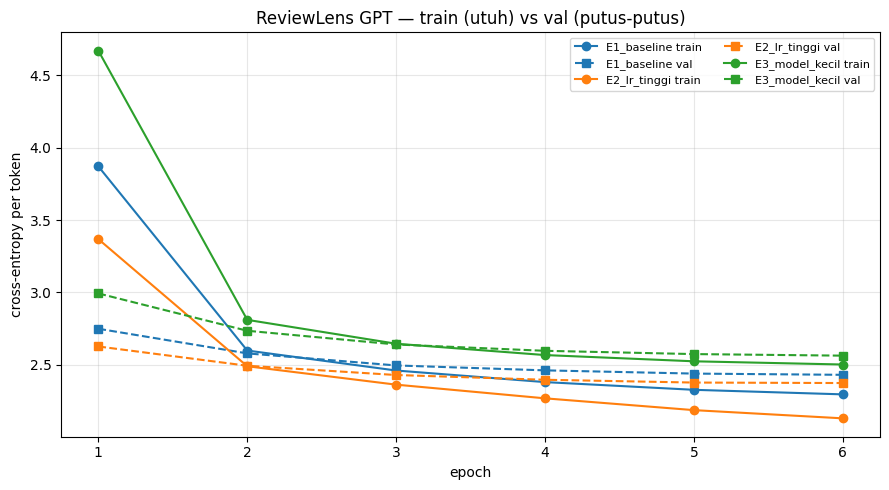

Disimpan: /kaggle/working/runs/loss_curves.png


,nama,parameter,lr,final train loss,best val loss,val perplexity,best epoch,durasi (s)
0,E1_baseline,4720640,0.0003,2.2959,2.4309,11.37,6,210.5
1,E2_lr_tinggi,4720640,0.0010,2.1302,2.3741,10.74,6,214.2
2,E3_model_kecil,1177344,0.0003,2.5021,2.5633,12.98,6,73.4


Model terbaik: E2_lr_tinggi (best val loss 2.3741, epoch 6)


In [12]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

fig, ax = plt.subplots(figsize=(9, 5))
for i, r in enumerate(RESULTS):
    color = f"C{i}"
    ep = [h["epoch"] for h in r["history"]]
    ax.plot(ep, [h["train_loss"] for h in r["history"]], "-o", color=color, label=f"{r['name']} train")
    ax.plot(ep, [h["val_loss"] for h in r["history"]], "--s", color=color, label=f"{r['name']} val")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("epoch")
ax.set_ylabel("cross-entropy per token")
ax.set_title("ReviewLens GPT — train (utuh) vs val (putus-putus)" + (" [QUICK_TEST]" if QUICK_TEST else ""))
ax.grid(alpha=0.3)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
LOSS_PNG = RUNS_DIR / "loss_curves.png"
fig.savefig(LOSS_PNG, dpi=120)
plt.show()
print("Disimpan:", LOSS_PNG)

COMPARE = pd.DataFrame([{
    "nama": r["name"],
    "parameter": r["n_parameters"],
    "lr": r["lr"],
    "final train loss": round(r["final_train_loss"], 4),
    "best val loss": round(r["best_val_loss"], 4),
    "val perplexity": round(r["val_perplexity"], 2),
    "best epoch": r["best_epoch"],
    "durasi (s)": round(r["duration_seconds"], 1),
} for r in RESULTS])
display(COMPARE)
BEST = min(RESULTS, key=lambda r: r["best_val_loss"])
print(f"Model terbaik: {BEST['name']} (best val loss {BEST['best_val_loss']:.4f}, epoch {BEST['best_epoch']})")

## Bagian 9 — Generate insight dengan model terbaik

`best.pt` dimuat ulang (dengan `map_location`, sehingga checkpoint GPU juga bisa dibuka di CPU), dan vocabulary dibaca
dari salinan di folder run (`ckpt["vocab_path"]`).

- `parse_generation(text)` (INTERFACES §10): ambil teks di antara `<pos>/<neg>/<sug>/<eos>`, pecah dengan `<sep>`,
  buang `<none>`, dedup. Valid jika `<pos>`, `<neg>`, `<sug>`, `<eos>` masing-masing muncul **tepat sekali dan berurutan**.
- `generate_insight(review)`: `clean_text` → `format_prompt` (ulasan ≤ 79 kata) → `encode` →
  `model.generate(max_new_tokens=MAX_NEW_TOKENS, temperature=0, eos_id=EOS)` (greedy) → `decode` → `parse_generation`.

In [13]:
BEST_DIR = Path(BEST["run_dir"])
BEST_CKPT_PATH = BEST_DIR / "best.pt"
best_ckpt = load_checkpoint(BEST_CKPT_PATH, DEVICE)
best_tokenizer = WordTokenizer.load(BEST_DIR / best_ckpt["vocab_path"])
check("vocab salinan run == vocab training", best_tokenizer == tokenizer)
best_model = MiniGPT(ModelConfig(**best_ckpt["model_cfg"])).to(DEVICE)
best_model.load_state_dict(best_ckpt["model_state"])
best_model.eval()
print(f"Dimuat: {BEST_CKPT_PATH} (epoch {best_ckpt['epoch']}, best val loss {best_ckpt['best_val_loss']:.4f})")

MARKERS = ("<pos>", "<neg>", "<sug>", "<eos>")
SECTION_OF = {"<pos>": "positives", "<neg>": "pain_points", "<sug>": "suggestions"}
DROP_TOKENS = {"<none>", "<pad>", "<bos>", "<review>"}


def parse_generation(text):
    """-> (positives, pain_points, suggestions, valid_format). Toleran terhadap output rusak."""
    tokens = text.split()
    valid = [t for t in tokens if t in MARKERS] == list(MARKERS)
    out = {"positives": [], "pain_points": [], "suggestions": []}
    section, buf = None, []

    def flush():
        phrase = " ".join(t for t in buf if t not in DROP_TOKENS)
        if section is not None and phrase and phrase not in out[section]:
            out[section].append(phrase)
        buf.clear()

    for t in tokens:
        if t == "<eos>":
            break
        if t in SECTION_OF:
            flush()
            section = SECTION_OF[t]
        elif t == "<sep>":
            flush()
        else:
            buf.append(t)
    flush()
    return out["positives"], out["pain_points"], out["suggestions"], valid


def generate_insight(review, model=best_model, tok=best_tokenizer):
    review_clean = clean_text(review)
    if not review_clean:   # kosong setelah dibersihkan -> model tidak dipanggil
        return {"review": review, "review_clean": "", "positives": [], "pain_points": [],
                "suggestions": [], "raw_output": "", "valid_format": False}
    prompt_ids = tok.encode(format_prompt(review_clean))
    idx = torch.tensor([prompt_ids], dtype=torch.long, device=DEVICE)
    out = model.generate(idx, max_new_tokens=MAX_NEW_TOKENS, temperature=0.0, eos_id=EOS)
    raw = tok.decode(out[0, len(prompt_ids) - 1:].tolist())   # mulai dari <pos> terakhir prompt
    pos, neg, sug, valid = parse_generation(raw)
    return {"review": review, "review_clean": review_clean, "positives": pos, "pain_points": neg,
            "suggestions": sug, "raw_output": raw, "valid_format": valid}


# Sanity check parser pada output buatan (bukan output model).
check("parse_generation: format valid",
      parse_generation("<pos> a b <sep> a b <neg> <none> <sug> <none> <eos>") == (["a b"], [], [], True))
check("parse_generation: output rusak tidak crash dan tidak valid",
      parse_generation("<pos> x <pos> y")[3] is False and parse_generation("")[3] is False)

rng = random.Random(SEED)
for i, rec in enumerate(rng.sample(RECORDS["test"], min(10, len(RECORDS["test"]))), 1):
    g = generate_insight(rec["review"])
    print(f"--- contoh {i} ---------------------------------------------------------------")
    print("Ulasan      :", rec["review"], f"[{rec['sentiment']}]")
    print("Silver label:", {"positives": rec["positives"], "pain_points": rec["pain_points"],
                            "suggestions": rec["suggestions"]})
    print("Model       :", {"positives": g["positives"], "pain_points": g["pain_points"],
                            "suggestions": g["suggestions"]}, "| valid" if g["valid_format"] else "| TIDAK valid")
    print("raw_output  :", g["raw_output"])

[PASS] vocab salinan run == vocab training
Dimuat: /kaggle/working/runs/E2_lr_tinggi/best.pt (epoch 6, best val loss 2.3741)
[PASS] parse_generation: format valid
[PASS] parse_generation: output rusak tidak crash dan tidak valid
--- contoh 1 ---------------------------------------------------------------
Ulasan      : pengiriman cepat packing aman rapi barang berfungsi sesuai harapan [positive]
Silver label: {'positives': ['pengiriman cepat', 'kemasan rapi dan aman', 'produk berfungsi dengan baik'], 'pain_points': [], 'suggestions': []}
Model       : {'positives': ['pengiriman cepat', 'kemasan rapi dan aman', 'barang sesuai deskripsi'], 'pain_points': [], 'suggestions': []} | valid
raw_output  : <pos> pengiriman cepat <sep> kemasan rapi dan aman <sep> barang sesuai deskripsi <neg> <none> <sug> <none> <eos>
--- contoh 2 ---------------------------------------------------------------
Ulasan      : barang bagus senin pesan selasa sampai mantap [positive]
Silver label: {'positives': ['kual

## Bagian 10 — Evaluasi (kunci sama dengan INTERFACES §11)

| Kunci | Definisi | Data |
|---|---|---|
| `test_perplexity` | `exp(rata-rata NLL per token)` atas posisi `y != IGNORE_INDEX` (teacher forcing, sama dengan loss training) | **seluruh** test set |
| `format_validity` | proporsi output dengan `valid_format=True` | `N_EVAL` contoh pertama test |
| `aspect_f1` | micro-F1 himpunan frasa hasil generate vs silver label, per bagian dan gabungan (`micro`); frasa di luar lexicon otomatis false positive | `N_EVAL` contoh pertama |
| `exact_match` | proporsi contoh yang ketiga himpunan frasanya sama persis dengan silver label | `N_EVAL` contoh pertama |

> **Pembanding = silver label** dari `label_review` (aturan lexicon), **bukan anotasi manusia**. Skor tinggi berarti
> model meniru pelabelan berbasis aturan; ini bukan bukti akurasi terhadap penilaian manusia.

Jika suatu bagian tidak punya frasa sama sekali di silver label maupun prediksi, F1 bagian itu didefinisikan 1.0.

In [14]:
SECTIONS = ("positives", "pain_points", "suggestions")
LEXICON_PHRASES = {p for a in ASPECTS for p in (a.pos_phrase, a.neg_phrase, a.suggestion)}


def f1_from(tp, fp, fn):
    denom = 2 * tp + fp + fn
    return 1.0 if denom == 0 else 2 * tp / denom


t0 = time.time()
test_nll = estimate_loss(best_model, test_loader, DEVICE)
eval_records = RECORDS["test"][:N_EVAL]
counts = {s: {"tp": 0, "fp": 0, "fn": 0} for s in SECTIONS}
n_valid = n_exact = n_out_of_lexicon = 0
for rec in eval_records:
    g = generate_insight(rec["review"])
    n_valid += g["valid_format"]
    exact = True
    for s in SECTIONS:
        pred, gold = set(g[s]), set(rec[s])
        counts[s]["tp"] += len(pred & gold)
        counts[s]["fp"] += len(pred - gold)
        counts[s]["fn"] += len(gold - pred)
        n_out_of_lexicon += len(pred - LEXICON_PHRASES)
        exact &= pred == gold
    n_exact += exact

aspect_f1 = {s: f1_from(**counts[s]) for s in SECTIONS}
aspect_f1["micro"] = f1_from(*(sum(counts[s][k] for s in SECTIONS) for k in ("tp", "fp", "fn")))
EVAL = {
    "split": "test",
    "checkpoint": str(BEST_CKPT_PATH),
    "n_examples_perplexity": len(test_ds),
    "n_examples_generation": len(eval_records),
    "test_perplexity": math.exp(test_nll),
    "format_validity": n_valid / len(eval_records),
    "aspect_f1": aspect_f1,
    "exact_match": n_exact / len(eval_records),
}
check("kunci eval sesuai INTERFACES §11",
      set(EVAL) == {"split", "checkpoint", "n_examples_perplexity", "n_examples_generation", "test_perplexity",
                    "format_validity", "aspect_f1", "exact_match"}
      and set(aspect_f1) == {"positives", "pain_points", "suggestions", "micro"})

print(f"Model: {BEST['name']}  |  waktu evaluasi {time.time() - t0:.1f}s  |  pembanding: SILVER LABEL")
print(f"test_perplexity     : {EVAL['test_perplexity']:.3f}   (n={EVAL['n_examples_perplexity']:,} sekuens)")
print(f"format_validity     : {EVAL['format_validity']:.3f}   (n={EVAL['n_examples_generation']})")
for s in (*SECTIONS, "micro"):
    print(f"aspect_f1[{s:11s}]: {aspect_f1[s]:.3f}")
print(f"exact_match         : {EVAL['exact_match']:.3f}")
print(f"(info) frasa hasil generate di luar lexicon: {n_out_of_lexicon}")

[PASS] kunci eval sesuai INTERFACES §11
Model: E2_lr_tinggi  |  waktu evaluasi 19.5s  |  pembanding: SILVER LABEL
test_perplexity     : 10.991   (n=3,921 sekuens)
format_validity     : 1.000   (n=500)
aspect_f1[positives  ]: 0.927
aspect_f1[pain_points]: 0.772
aspect_f1[suggestions]: 0.774
aspect_f1[micro      ]: 0.875
exact_match         : 0.800
(info) frasa hasil generate di luar lexicon: 118


## Bagian 11 — Demo Customer Insight Report

Delapan ulasan baru berbahasa slang/typo. **Insight dihasilkan oleh `MiniGPT.generate`**. Hasil `label_review`
(aturan, tanpa sentimen) ditampilkan **hanya sebagai pembanding**, tidak dipakai untuk laporan.

Laporan menghitung frekuensi setiap frasa di seluruh ulasan (top 5, persentase = jumlah ulasan yang menyebut frasa ÷
jumlah ulasan × 100).

In [15]:
from collections import Counter

DEMO_REVIEWS = [
    "barangnya mantul bgt, pengiriman cepet bgt",
    "kurirnya lama bgt, paketnya penyok pula",
    "tv nya gak nyala pas dtg, kecewa bgt",
    "hrg murah tp kualitas oke lah, recomended",
    "sesui deskripsi, packing rapih, seller ramah",
    "flashdisk kw, kapasitas gak sesuai, jgn beli",
    "pengiriman lelet, brg sampe dlm keadaan rusak",
    "mantaaap, ori, garansi resmi, makasih gan",
]

demo_rows, freq = [], {s: Counter() for s in SECTIONS}
for review in DEMO_REVIEWS:
    g = generate_insight(review)
    rule = label_review(g["review_clean"], None)
    for s in SECTIONS:
        freq[s].update(g[s])
    demo_rows.append({
        "ulasan": review,
        "model: positives": "; ".join(g["positives"]) or "-",
        "model: pain_points": "; ".join(g["pain_points"]) or "-",
        "model: suggestions": "; ".join(g["suggestions"]) or "-",
        "valid": g["valid_format"],
        "pembanding label_review": "; ".join(rule.positives + rule.pain_points) or "-",
    })
with pd.option_context("display.max_colwidth", 60):
    display(pd.DataFrame(demo_rows))

TITLES = {"positives": "Hal yang disukai", "pain_points": "Keluhan utama", "suggestions": "Saran perbaikan"}
DEMO_REPORT = {"n_reviews": len(DEMO_REVIEWS)}
print(f"\nCUSTOMER INSIGHT REPORT — {len(DEMO_REVIEWS)} ulasan (sumber: MiniGPT.generate, model {BEST['name']})")
for s in SECTIONS:
    top = [{"text": t, "count": c, "percentage": 100 * c / len(DEMO_REVIEWS)} for t, c in freq[s].most_common(5)]
    DEMO_REPORT[s] = top
    print(f"\n{TITLES[s]}:")
    for item in top or [{"text": "(tidak ada)", "count": 0, "percentage": 0.0}]:
        print(f"  - {item['text']:45s} {item['count']}x  ({item['percentage']:.1f}%)")

,ulasan,model: positives,model: pain_points,model: suggestions,valid,pembanding label_review
0,"barangnya mantul bgt, pengiriman cepet bgt",kualitas produk bagus; pengiriman cepat,-,-,True,kualitas produk bagus; pengiriman cepat
1,"kurirnya lama bgt, paketnya penyok pula",-,pengiriman lambat,percepat proses pengiriman,True,pengiriman lambat
2,"tv nya gak nyala pas dtg, kecewa bgt",-,produk rusak atau cacat,perketat quality control sebelum pengiriman,True,produk rusak atau cacat
3,"hrg murah tp kualitas oke lah, recomended",harga terjangkau; kualitas produk bagus,-,-,True,harga terjangkau; kualitas produk bagus
4,"sesui deskripsi, packing rapih, seller ramah",barang sesuai deskripsi; kemasan rapi dan aman; pelayana...,-,-,True,barang sesuai deskripsi; kemasan rapi dan aman; pelayana...
5,"flashdisk kw, kapasitas gak sesuai, jgn beli",-,keaslian produk diragukan,pastikan keaslian produk yang dijual,True,keaslian produk diragukan; barang tidak sesuai deskripsi
6,"pengiriman lelet, brg sampe dlm keadaan rusak",-,pengiriman lambat; kualitas produk buruk; produk rusak a...,percepat proses pengiriman; tingkatkan kualitas bahan pr...,True,pengiriman lambat; produk rusak atau cacat
7,"mantaaap, ori, garansi resmi, makasih gan",produk asli dan original; garansi resmi dan jelas,-,-,True,produk asli dan original; garansi resmi dan jelas



CUSTOMER INSIGHT REPORT — 8 ulasan (sumber: MiniGPT.generate, model E2_lr_tinggi)

Hal yang disukai:
  - kualitas produk bagus                         2x  (25.0%)
  - pengiriman cepat                              1x  (12.5%)
  - harga terjangkau                              1x  (12.5%)
  - barang sesuai deskripsi                       1x  (12.5%)
  - kemasan rapi dan aman                         1x  (12.5%)

Keluhan utama:
  - pengiriman lambat                             2x  (25.0%)
  - produk rusak atau cacat                       2x  (25.0%)
  - keaslian produk diragukan                     1x  (12.5%)
  - kualitas produk buruk                         1x  (12.5%)

Saran perbaikan:
  - percepat proses pengiriman                    2x  (25.0%)
  - perketat quality control sebelum pengiriman   2x  (25.0%)
  - pastikan keaslian produk yang dijual          1x  (12.5%)
  - tingkatkan kualitas bahan produk              1x  (12.5%)


## Bagian 12 — Menyimpan hasil

- `runs/results.json`: commit, konfigurasi, hasil ketiga eksperimen (history lengkap), model terbaik, metrik evaluasi,
  laporan demo, hasil pemeriksaan.
- `runs/eval.json`: metrik evaluasi dengan kunci INTERFACES §11.

Di Kaggle, isi `/kaggle/working` **hilang** saat sesi berakhir kecuali notebook disimpan dengan **Save Version**
atau file diunduh manual. Checkpoint dan dataset turunan tidak di-commit ke GitHub.

In [16]:
from datetime import datetime, timezone

check("CSV asli tidak berubah (SHA-256 sama)", sha256_file(CSV_PATH) == CSV_SHA256_BEFORE)

RESULTS_JSON = RUNS_DIR / "results.json"
EVAL_JSON = RUNS_DIR / "eval.json"
results_doc = {
    "notebook": "02_train_evaluate",
    "created_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "mode": "QUICK_TEST (bukan hasil eksperimen)" if QUICK_TEST else "full",
    "repository": {"url": REPO_URL, "branch": BRANCH, "commit": REPO_COMMIT},
    "dataset": {"csv_path": str(CSV_PATH), "sha256": CSV_SHA256_BEFORE},
    "environment": {"python": platform.python_version(), "torch": torch.__version__, "device": DEVICE,
                    "gpu": torch.cuda.get_device_name(0) if DEVICE.startswith("cuda") else None},
    "config": {"epochs": EPOCHS, "batch_size": BATCH_SIZE, "seed": SEED, "n_eval": N_EVAL,
               "train_subset": TRAIN_SUBSET, "warmup_steps": WARMUP_STEPS, "min_lr_ratio": MIN_LR_RATIO,
               "betas": [0.9, 0.95], "weight_decay": TrainConfig().weight_decay,
               "grad_clip": TrainConfig().grad_clip, "experiments": EXPERIMENTS},
    "data": {"records_jsonl": SPLIT_COUNTS, "vocab_size": VOCAB_SIZE, "unk_pct_val_reviews": UNK_VAL_PCT,
             "block_size": BLOCK_SIZE, "train_examples_used": len(train_ds)},
    "experiments": RESULTS,
    "failed_experiments": FAILED,
    "best_experiment": BEST["name"],
    "evaluation": EVAL,
    "evaluation_reference": "silver labels (labeling.label_review), not human annotation",
    "demo_report": DEMO_REPORT,
    "checks": CHECKS,
    "all_checks_passed": all(CHECKS.values()),
}
write_json(RESULTS_JSON, results_doc)
write_json(EVAL_JSON, EVAL)

downloads = [RESULTS_JSON, EVAL_JSON, LOSS_PNG, WORK_DIR / "prepare_data_stdout.txt",
             BEST_DIR / "best.pt", BEST_DIR / "vocab.json"]
for r in RESULTS:
    downloads += [Path(r["run_dir"]) / "history.json", Path(r["run_dir"]) / "last.pt"]
print(f"Semua pemeriksaan lulus: {all(CHECKS.values())} ({sum(CHECKS.values())}/{len(CHECKS)})")
print("\nFile yang perlu diunduh / disimpan (Save Version):")
for p in downloads:
    if p.exists():
        print(f"  ok     {p}  ({p.stat().st_size / 1e6:.2f} MB)")
    else:
        print(f"  HILANG {p}")
check("semua file output ada", all(p.exists() for p in downloads))
print("\nUntuk demo/inferensi cukup:", BEST_DIR / "best.pt", "dan", BEST_DIR / "vocab.json")

[PASS] CSV asli tidak berubah (SHA-256 sama)
Semua pemeriksaan lulus: True (16/16)

File yang perlu diunduh / disimpan (Save Version):
  ok     /kaggle/working/runs/results.json  (0.01 MB)
  ok     /kaggle/working/runs/eval.json  (0.00 MB)
  ok     /kaggle/working/runs/loss_curves.png  (0.08 MB)
  ok     /kaggle/working/prepare_data_stdout.txt  (0.00 MB)
  ok     /kaggle/working/runs/E2_lr_tinggi/best.pt  (56.97 MB)
  ok     /kaggle/working/runs/E2_lr_tinggi/vocab.json  (0.11 MB)
  ok     /kaggle/working/runs/E1_baseline/history.json  (0.00 MB)
  ok     /kaggle/working/runs/E1_baseline/last.pt  (56.97 MB)
  ok     /kaggle/working/runs/E2_lr_tinggi/history.json  (0.00 MB)
  ok     /kaggle/working/runs/E2_lr_tinggi/last.pt  (56.97 MB)
  ok     /kaggle/working/runs/E3_model_kecil/history.json  (0.00 MB)
  ok     /kaggle/working/runs/E3_model_kecil/last.pt  (14.29 MB)
[PASS] semua file output ada

Untuk demo/inferensi cukup: /kaggle/working/runs/E2_lr_tinggi/best.pt dan /kaggle/working/run